## Chargement et Analyse exploratoire des données

##### *Import Libraries*

In [142]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

#Importation des Alogorithmes 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

#Importe les métriques d'évaluation
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

##### *Load Dataset*

In [54]:
#lire le fichier CSV
df = pd.read_csv("../DatasetMental_Health/student_mental_health.csv")

df.head()  #afficher les 5 premières lignes du DataFrame

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


##### *Data Understanding*

In [55]:
print("Types de données des colonnes :", df.dtypes)
print("Nombre de lignes et de colonnes :", df.shape) 

Types de données des colonnes : Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object
Nombre de lignes et de colonnes : (2000, 17)


In [56]:
df.columns.tolist()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

Analyse de data : 
- 2000 lignes 
- 17 colonnes 
- 10 variables numériques 
- 7 variable catégoriels 
- info montre que il ya des valeurs manquants 
- Variable	Valeurs manquantes : Sleep_Hours(62),GPA(38),Social_Media_Hours(58),Financial_Stress(91),Family_Support(54),Attendance_Rate(47),Diet_Quality(69)

##### *Data Quality Audit*

In [58]:
#Verifier les valeurs manquantes
missing_values = df.isnull().sum()
print("Valeurs manquantes par colonne :\n", missing_values)

#verifier les items qui ont Social_Media_Hours > Screen_Time_Hours
print("Count items has Social_Media_Hours > Screen_Time_Hours :", df[df['Social_Media_Hours'] > df['Screen_Time_Hours']].shape[0])

Valeurs manquantes par colonne :
 Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64
Count items has Social_Media_Hours > Screen_Time_Hours : 37


In [59]:
#vérifier les valeurs dupliquées
duplicated=df.duplicated().sum()
print("Nombre de lignes dupliquées :", duplicated)

Nombre de lignes dupliquées : 0


In [60]:
#vérifier les IDs dupliquées 
duplicated_ids=df['Student_ID'].duplicated().sum()
print("Nombre d'IDs dupliquées :", duplicated_ids)

Nombre d'IDs dupliquées : 0


In [61]:
#Vérifier les valeurs uniques pour les colonnes catégorielles
categorical_columns = df.select_dtypes(include="str").columns.drop("Student_ID")  

for col in categorical_columns:
    print(df[col].value_counts(dropna=False))

Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [62]:
#Vérifier les valeurs numériques incohérentes 
df.describe().T   #Transpose the output for better readability

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [63]:
#Récuperer numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

print(numerical_columns.tolist())

['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


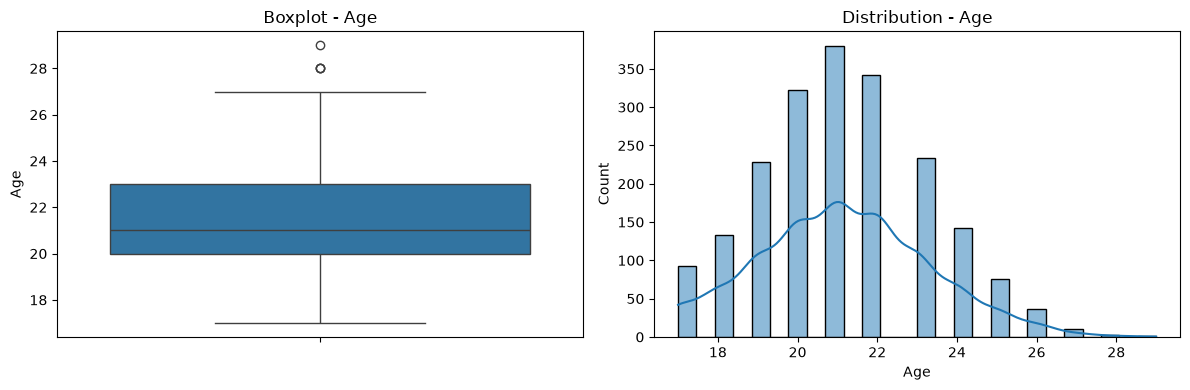

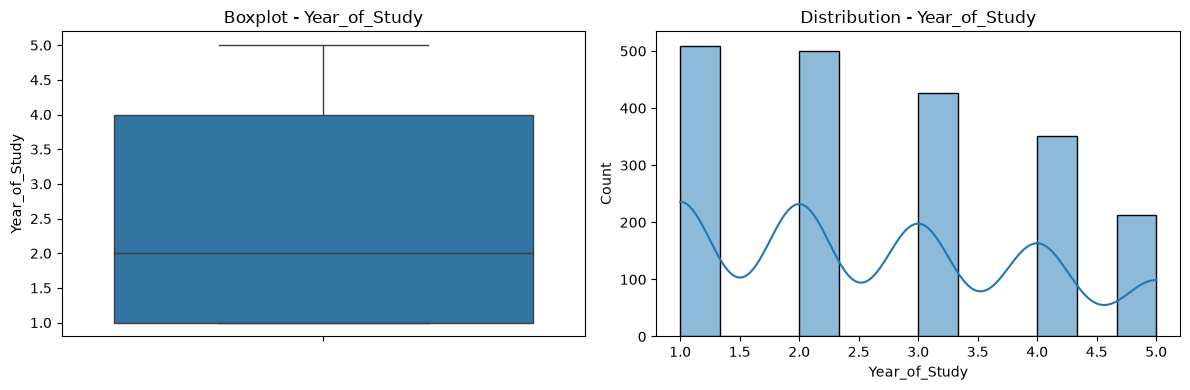

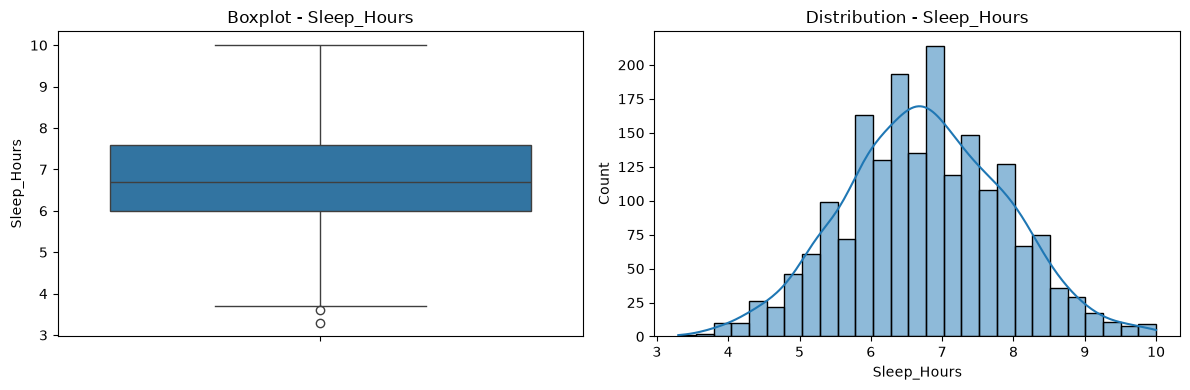

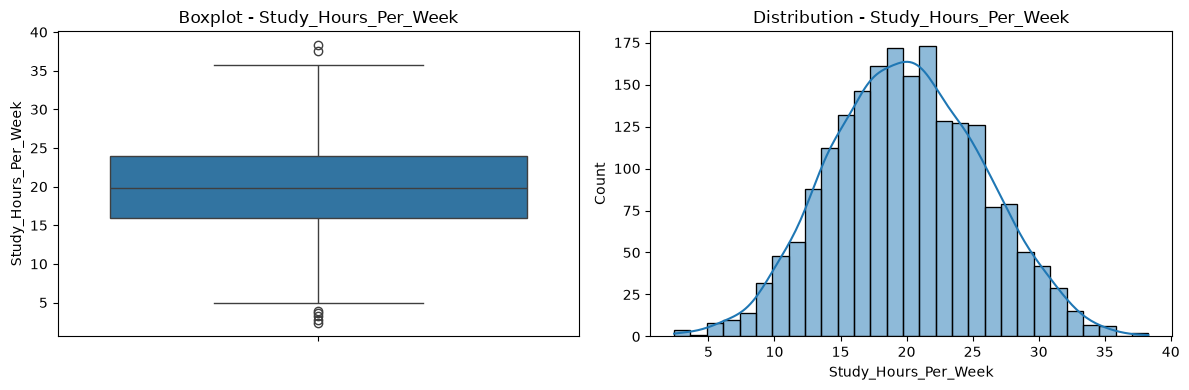

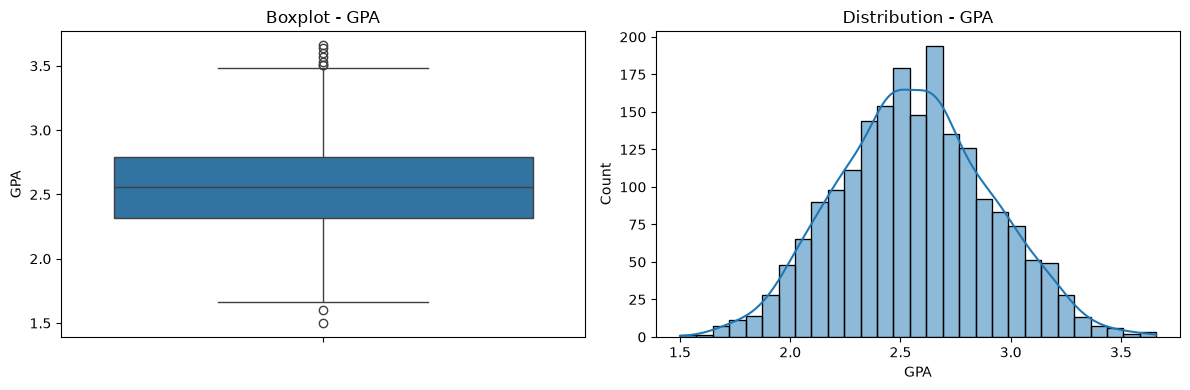

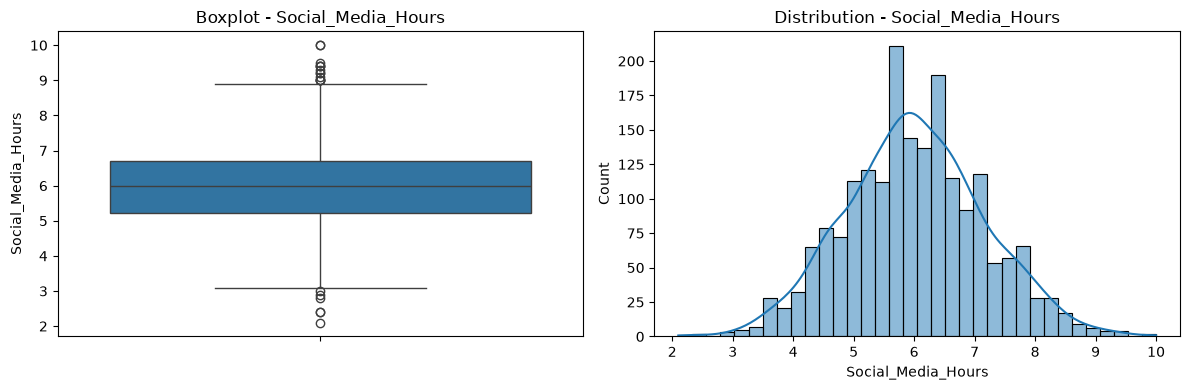

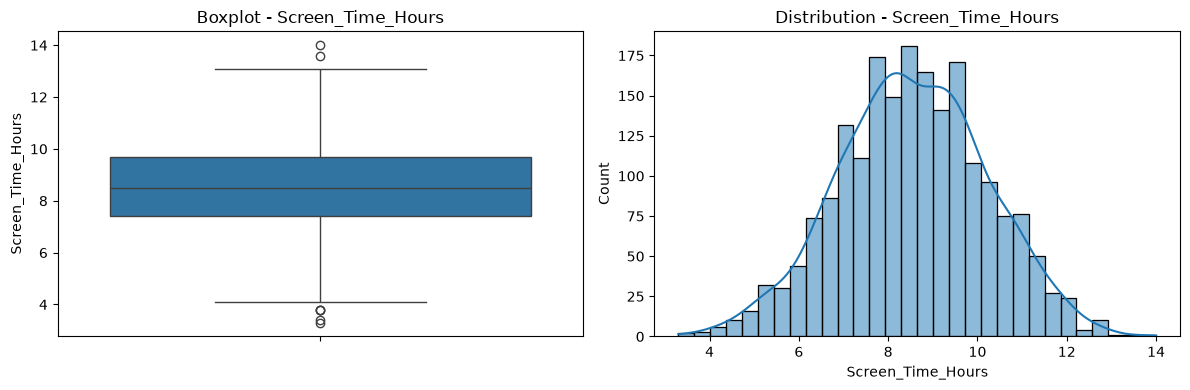

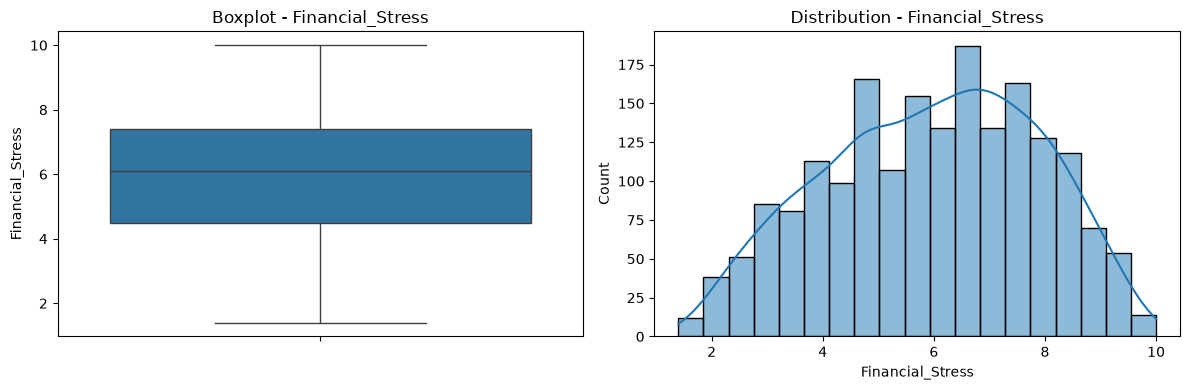

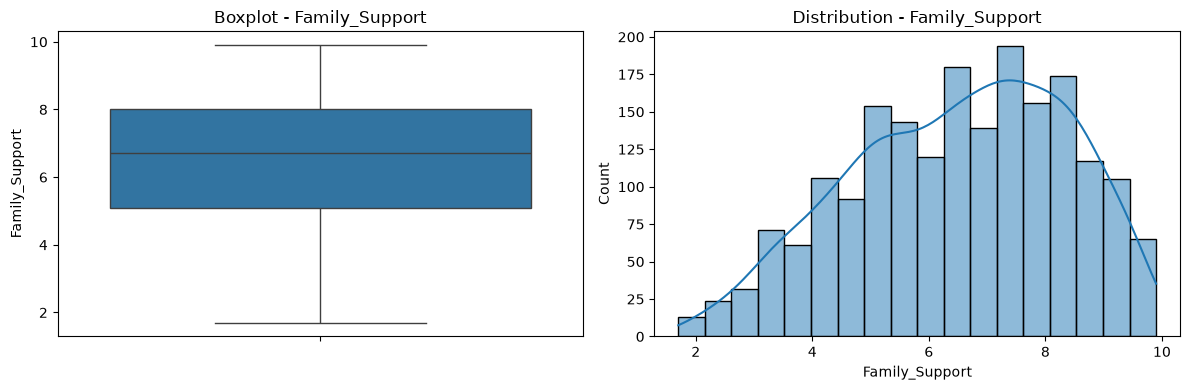

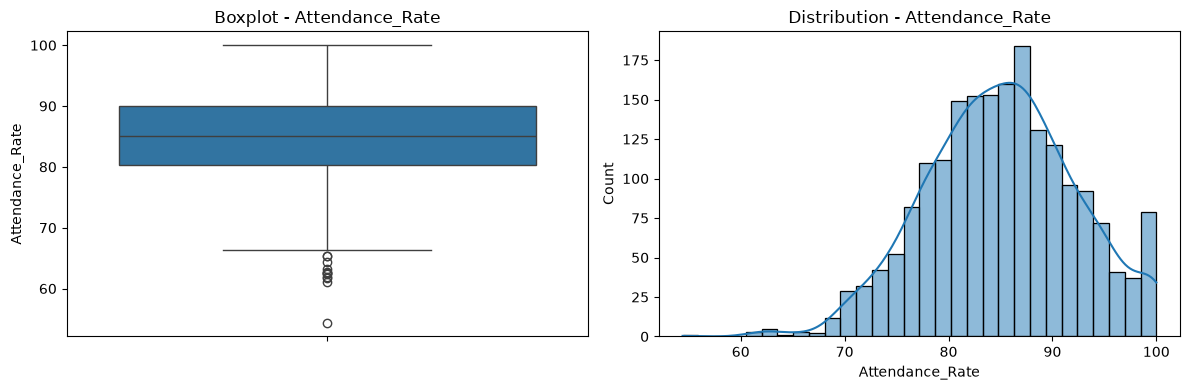

In [64]:
for col in numerical_columns:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Boxplot
    sns.boxplot(y=df[col], ax=axes[0])
    axes[0].set_title(f"Boxplot - {col}")

    # Distribution
    sns.histplot(df[col].dropna(), kde=True, ax=axes[1])
    axes[1].set_title(f"Distribution - {col}")

    plt.tight_layout()
    plt.show()

In [65]:
#Récupérer les outliers pour chaque colonne numérique(Méthode IQR)
outlier_results = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)  
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1  #calculer IQR signifie Interquartile Range

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable   ": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Number_of_Outliers": len(outliers),
        "pourcentage_d_outliers": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df = outlier_df[outlier_df["Number_of_Outliers"] > 0]

outlier_df

,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Number_of_Outliers,pourcentage_d_outliers
0,Age,20.00,23.00,3.00,15.50,27.50,4,0.20
2,Sleep_Hours,6.00,7.60,1.60,3.60,10.00,2,0.10
3,Study_Hours_Per_Week,16.00,24.00,8.00,4.00,36.00,7,0.35
4,GPA,2.32,2.79,0.47,1.61,3.50,9,0.45
5,Social_Media_Hours,5.22,6.70,1.48,3.01,8.91,20,1.00
6,Screen_Time_Hours,7.40,9.70,2.30,3.95,13.15,7,0.35
9,Attendance_Rate,80.30,90.00,9.70,65.75,104.55,12,0.60


##### *Distribution des classes*

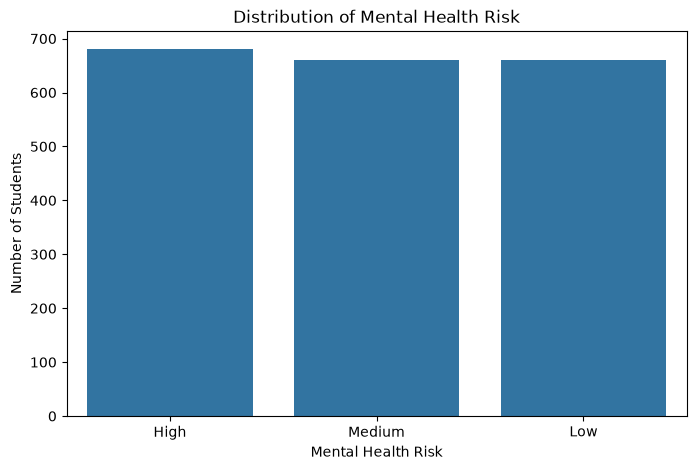

In [66]:
#Visualisation de la distribution du Variable cible 
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=df["Mental_Health_Risk"].value_counts().index
)

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

##### *Analyse des relations entre les variables explicatives et la cible*

In [67]:
# Define the target variable
target = "Mental_Health_Risk"

# Identify categorical and numerical features
categorical_features = df.select_dtypes(include=["str", "object"]).columns.tolist()
numerical_features = df.select_dtypes(include=["number"]).columns.tolist()

# Exclude the target and Student_ID from explanatory variables
categorical_features = [
    col for col in categorical_features
    if col not in [target, "Student_ID"]
]

numerical_features = [
    col for col in numerical_features
    if col != target
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']

Numerical Features:
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


##### relation entre variable catégoriels et Mental_health_risk

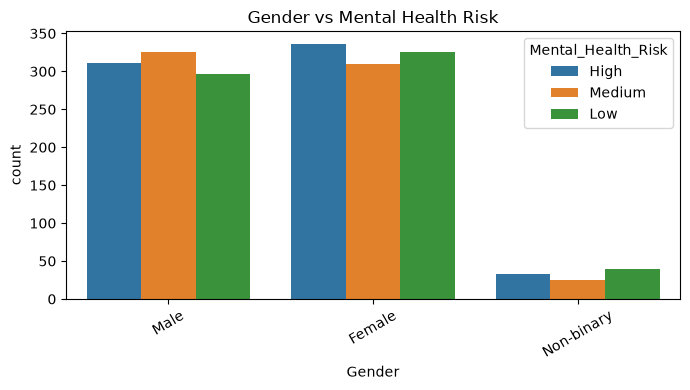

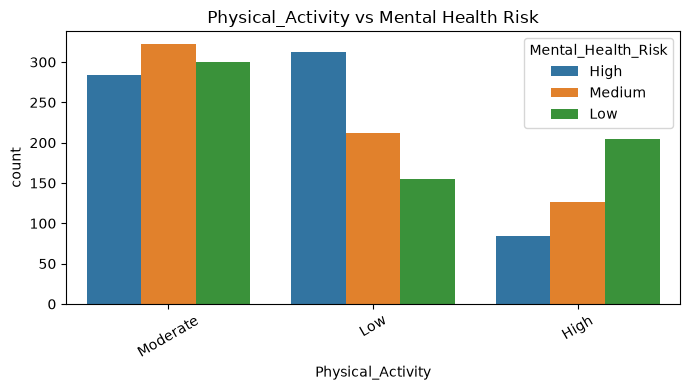

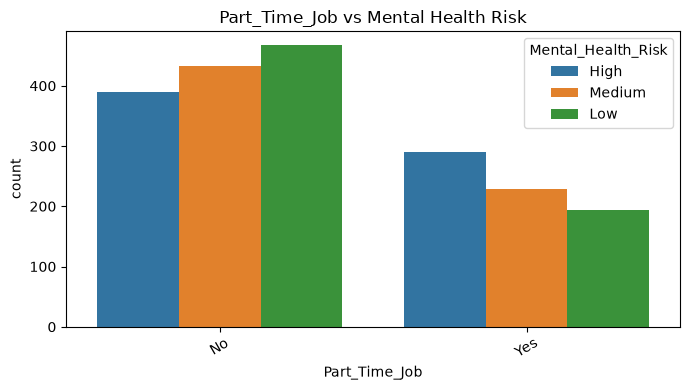

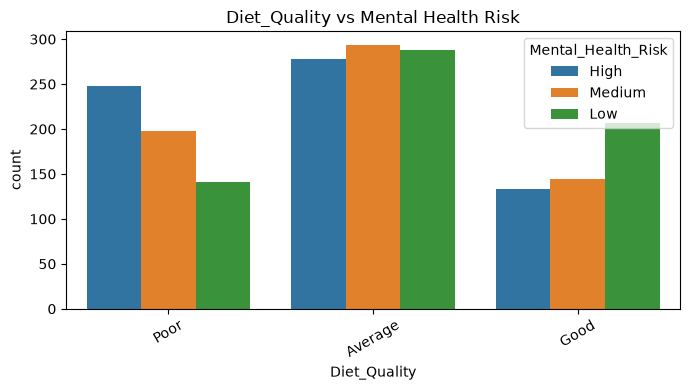

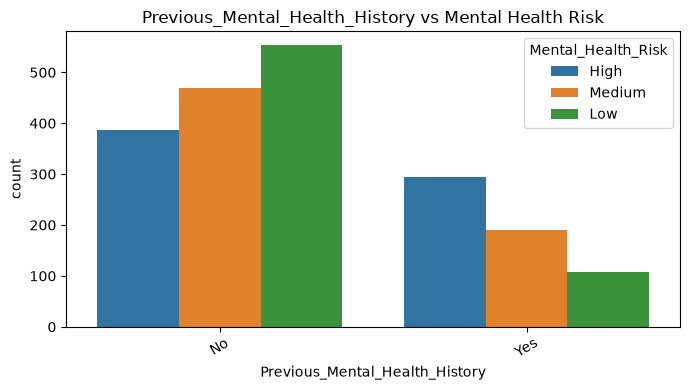

In [68]:
for col in categorical_features:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col,
        hue="Mental_Health_Risk"
    )

    plt.title(f"{col} vs Mental Health Risk")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

Résumé d'analyse de Relation : 
- genre de personne pas d'une relation avec mental health risk 
- plus l’activité physique augmente, plus le risque de santé mentale diminue.
- Part time job aide de diminue d'avoir le risque de santé mentale 
- plus la qualité de l’alimentation est bonne, plus le risque diminue
- un antécédent de santé mentale est fortement associé à un risque plus élevé.

##### relation entre variable numeric  et Mental_health_risk

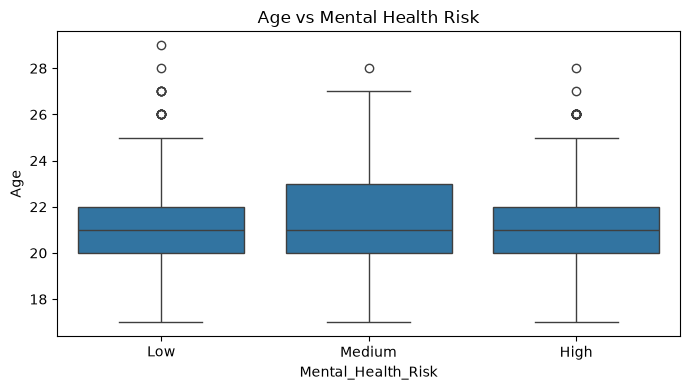

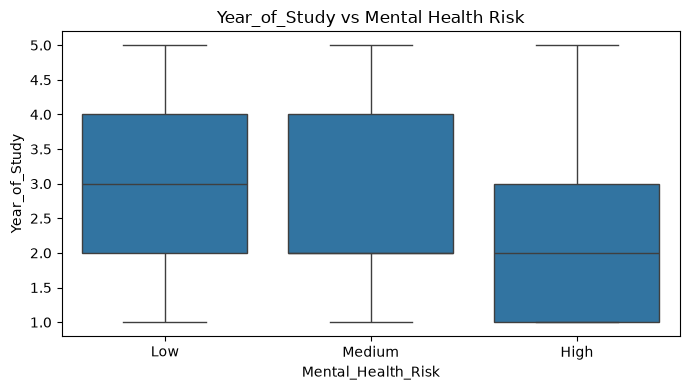

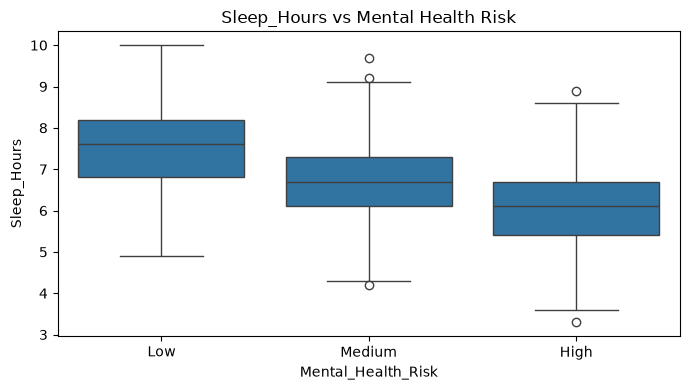

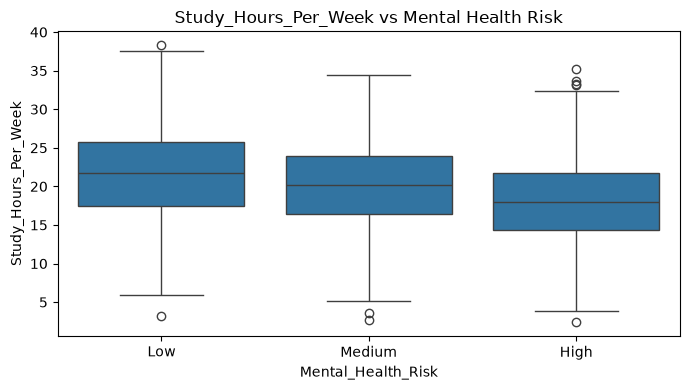

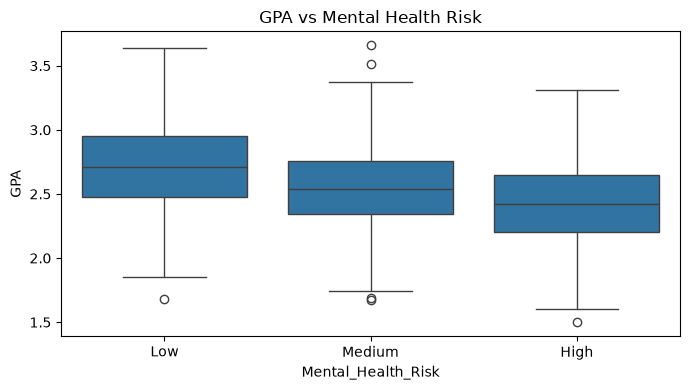

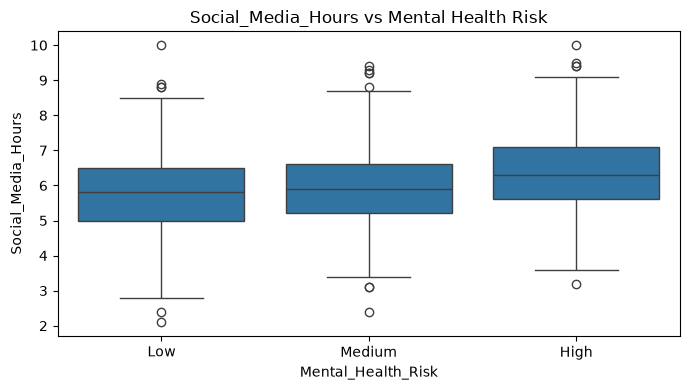

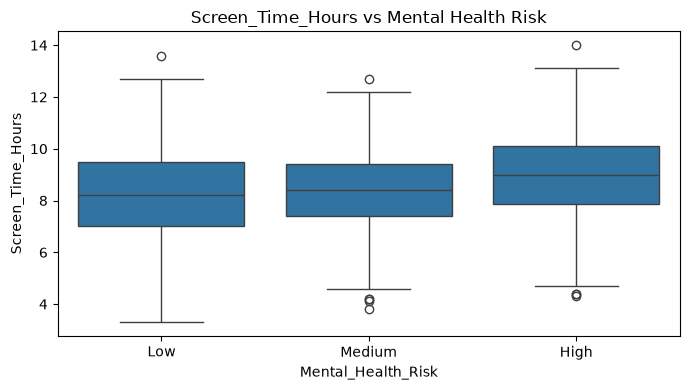

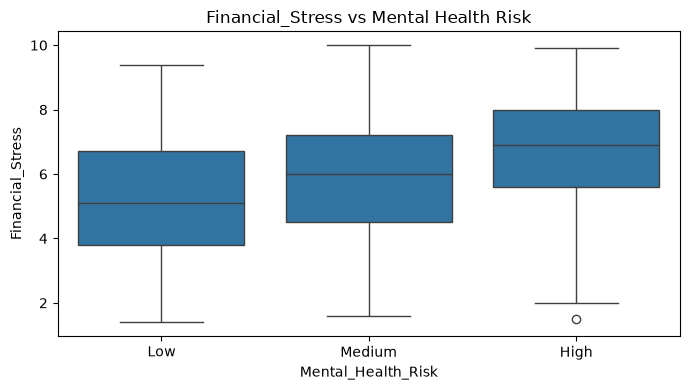

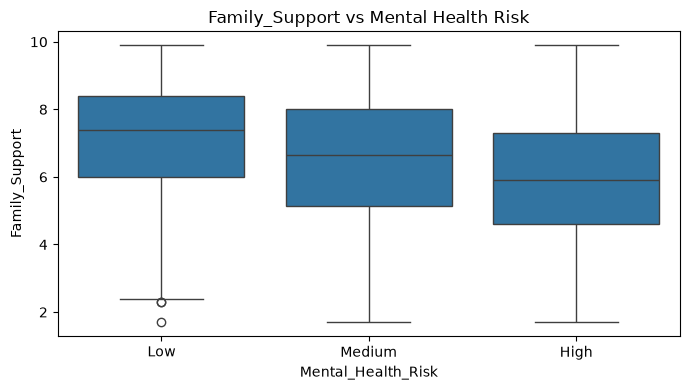

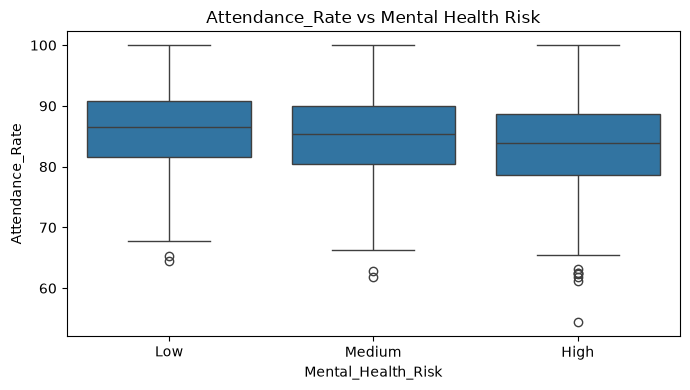

In [69]:
for col in numerical_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Mental_Health_Risk",
        y=col,
        order=["Low", "Medium", "High"]
    )

    plt.title(f"{col} vs Mental Health Risk")
    plt.tight_layout()
    plt.show()

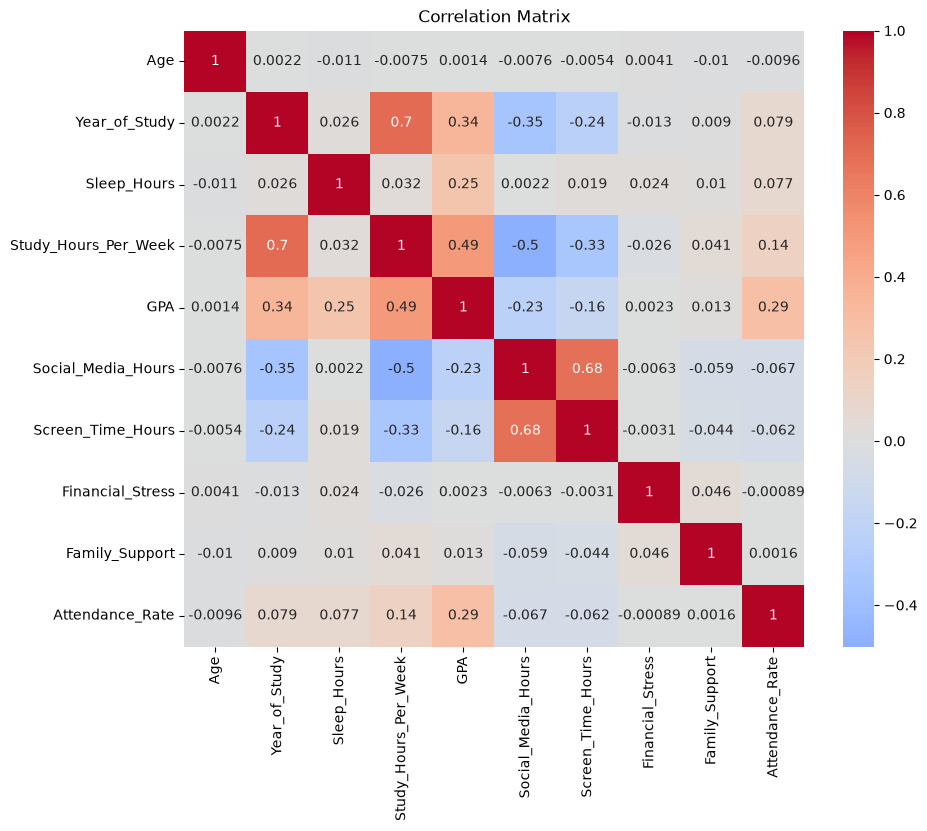

In [70]:
#Matrice de Corrélation
correlation_matrix = df[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True, 
    cmap='coolwarm', 
    center=0
    )
plt.title('Correlation Matrix')
plt.show()

#### identifier les variables les plus fortement liées au niveau de risque

In [71]:
# Compare moyenne de variable numérique par niveau de risque de santé mentale
risk_analysis = df.groupby("Mental_Health_Risk")[numerical_features].mean().T

# Display the results
risk_analysis.round(2)

Mental_Health_Risk,High,Low,Medium
Age,21.14,21.11,21.14
Year_of_Study,2.36,2.90,2.64
Sleep_Hours,6.04,7.52,6.73
Study_Hours_Per_Week,18.36,21.70,19.98
GPA,2.42,2.72,2.55
Social_Media_Hours,6.35,5.76,5.92
Screen_Time_Hours,8.96,8.26,8.42
Financial_Stress,6.69,5.24,5.90
Family_Support,5.96,7.09,6.53
Attendance_Rate,83.77,86.33,85.19


## Transformation et préparation des données

In [72]:
#Split the dataset into training and testing sets

# Separate features and target
X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])
y = df["Mental_Health_Risk"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1600, 15)
X_test: (400, 15)
y_train: (1600,)
y_test: (400,)


In [73]:
# X_train.columns 

#### Traitement des valeurs manquantes (Missing Values)

In [74]:
#extrait nmbr valeur manquantes 

missing_values = X_train.isnull().sum()
missing_values = missing_values[missing_values > 0]    #affiche colunnes valeur manquantes 

print(missing_values)

Sleep_Hours           54
GPA                   36
Social_Media_Hours    48
Financial_Stress      76
Family_Support        36
Attendance_Rate       39
Diet_Quality          55
dtype: int64


In [75]:
#counts  Diet_Quality 
print(X_train["Diet_Quality"].value_counts())

Diet_Quality
Average    687
Poor       476
Good       382
Name: count, dtype: int64


In [76]:
#Préparer les imputers 
from sklearn.impute import SimpleImputer

numerical_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(include=["object","str"]).columns

#crée les imputer 
numerical_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

print("columns numeric :", list(numerical_columns))
print("columns catégoriques :", list(categorical_columns))

columns numeric : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
columns catégoriques : ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


In [81]:
#Application de l'imputation 

X_train[numerical_columns] = numerical_imputer.fit_transform(
    X_train[numerical_columns]
)
X_train[categorical_columns] = categorical_imputer.fit_transform(
    X_train[categorical_columns]
)


X_test[numerical_columns] = numerical_imputer.transform(
    X_test[numerical_columns]
)
X_test[categorical_columns] = categorical_imputer.transform(
    X_test[categorical_columns]
)

#Vérifier les valeurs manquantes après l'imputation
missing_values_train = X_train.isnull().sum().sum()
missing_values_test = X_test.isnull().sum().sum()
print("Valeurs manquantes Training : ", missing_values_train)
print("Valeurs manquantes Test : ", missing_values_test)


Valeurs manquantes Training :  0
Valeurs manquantes Test :  0


#### Détection des valeurs aberrantes (Outliers)

In [ ]:
# Detect outliers(IQR)
outliers_count = {}

for col in numerical_columns:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ]

    outliers_count[col] = len(outliers)

pd.Series(outliers_count, name="Outliers Count")

Age                      2
Year_of_Study            0
Sleep_Hours              9
Study_Hours_Per_Week     7
GPA                      8
Social_Media_Hours      16
Screen_Time_Hours        7
Financial_Stress         0
Family_Support           0
Attendance_Rate         10
Name: Outliers Count, dtype: int64

Aprées l'Analyse Que on'a et la détection des outliers avec IQR en décide de ne pas remove par ce que il sont des outliers logiques 

#### Encodage des variables catégorielles/ la standardisation des variables numériques

In [128]:
#Définir les colonnes 
num_cols = [
    'Age',
    'Year_of_Study',
    'Sleep_Hours',
    'Study_Hours_Per_Week',
    'GPA',
    'Social_Media_Hours',
    'Screen_Time_Hours',
    'Financial_Stress',
    'Family_Support',
    'Attendance_Rate'
]

nominal_cols = [
    'Gender',
    'Part_Time_Job',
    'Previous_Mental_Health_History'
]

ordinal_cols = [
    'Physical_Activity',
    'Diet_Quality'
]

In [ ]:
#Définition ordre odinal 
ordinal_categories = [
    ["Low", "Moderate", "High"],
    ["Poor", "Average", "Good"]
]

In [126]:
#Création des encodeurs 
nominal_encoder = OneHotEncoder(handle_unknown='ignore')
ordinal_encoder = OrdinalEncoder(categories=ordinal_categories)

#crée StandarScaler
scaler = StandardScaler()

In [127]:
#Appliquer Columntransfer 
preprocessor = ColumnTransformer(
    transformers=[
        ('num',StandardScaler(), num_cols),
        ('nominal', nominal_encoder, nominal_cols),
        ('ordinal', ordinal_encoder, ordinal_cols)
    ],
    remainder='passthrough'  #conserve les colonnes numeric  sans modification
)

In [ ]:
#Crée Un pipeline 
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)
])

In [107]:
#Application d'encodage 
X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

#### Gérer le déséquilibre des classes 

In [112]:
#vérifier la distribution de la variable cible dans l'ensemble d'entraînement
print(y_train.value_counts())

Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64


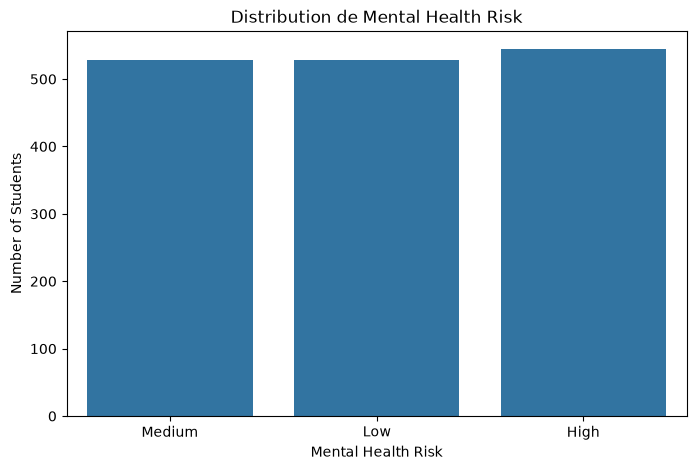

In [123]:
#Visualiser la distribution 
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y_train,
)

plt.title('Distribution de Mental Health Risk')
plt.xlabel('Mental Health Risk')
plt.ylabel('Number of Students')
plt.show()

## Entraînement et comparaison des modèles

In [ ]:
# Declarer Model d'entrainement 
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

pipelines = {
    name: Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    for name, model in models.items()
}

In [ ]:
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} : entraînement terminé")

Logistic Regression : entraînement terminé
Random Forest : entraînement terminé
KNN : entraînement terminé


In [ ]:
#Calculer Les metriques d'évaluation 
results = []

for name, pipeline in pipelines.items():
    
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro'),
        'Recall': recall_score(y_test, y_pred, average='macro'),
        'F1-Score': f1_score(y_test, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(
            y_test,
            y_proba,
            multi_class='ovr',
            average='macro',                                    #calcule metric pour chaque class  puis calcule la moyenne
            labels=pipeline.classes_
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7575,0.7570,0.7568,0.7569,0.9140
1,Random Forest,0.6800,0.6767,0.6794,0.6779,0.8482
2,KNN,0.5825,0.5661,0.5815,0.5703,0.7721


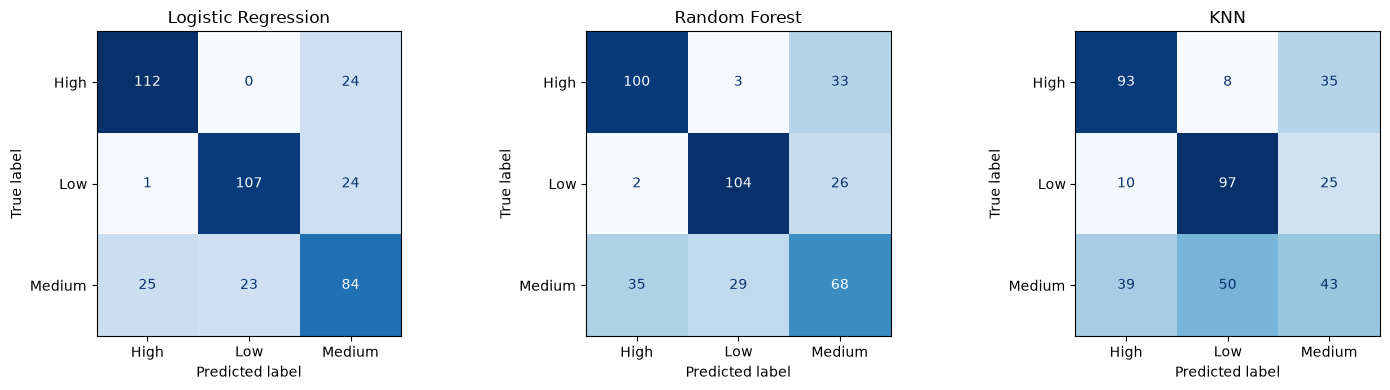

In [145]:
#Metric d'évaluation 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

Trois modèles (Logistic Regression, Random Forest et KNN) ont été entraînés et évalués à l'aide d'Accuracy, Precision, Recall, F1-score et ROC-AUC.

La **Logistic Regression** a obtenu les meilleures performances avec 75.75 % d'Accuracy et 91.40 % de ROC-AUC. Elle est retenue comme meilleur modèle parmi les trois testés.